# Nightingale's Rose

DS 2023 | Communicating with Data

*Author: Claudius (Claude Opus 5.5, Anthropic), November 2026*

```{note}
This notebook was written by Claudius, an AI model made by Anthropic, at the request of the course author.

It was drafted while reproducing Nightingale's 1858 plate in Matplotlib, and the findings about stacking order come from that work.
```

## Overview

A **polar area diagram** divides a circle into equal slices, one for each category, and draws a wedge in each slice.

The size of each wedge shows a quantity.

The categories are usually cyclical, like months or compass directions, so going around the circle is meaningful.

The most famous example is Florence Nightingale's *Diagram of the Causes of Mortality in the Army in the East*.

It appeared in her 1858 book *Notes on Matters Affecting the Health, Efficiency, and Hospital Administration of the British Army*, printed by Harrison in London.

The data came from tables prepared by the statistician William Farr.

The diagram is often called a **rose** or a **coxcomb**.

It shows the monthly death rates of the British army in the Crimean War, from April 1854 to March 1856, split into three causes:

- **blue** for "preventible or mitigable zymotic diseases" (cholera, dysentery, typhus),
- **red** for wounds,
- **black** for all other causes.

Nightingale's point was simple and devastating.

Far more soldiers died of disease than of wounds, and most of those deaths could have been prevented.

Here is how the visual elements map to the data:

| Visual element | Data |
|---|---|
| The slice (30° of the circle) | a month |
| The order of slices, clockwise | time |
| The color of a wedge | the cause of death |
| The **area** of a wedge | the death rate |
| The two circles | the two years of the war |

## Use Cases

- **Months of the year**: deaths, sales, or rainfall by month, where December sits next to January.
- **Hours of the day**: website traffic or emergency calls by hour.
- **Compass directions**: a **wind rose** shows how often the wind blows from each direction.
- **Days of the week**: crimes or hospital admissions by weekday.

In each case the categories wrap around, and a circle shows that better than a line with two ends.

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Nightingale's table is included in R's `HistData` package, which the Rdatasets project publishes as CSV files.

In [2]:
url = 'https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/HistData/Nightingale.csv'
nightingale = pd.read_csv(url, index_col='rownames', parse_dates=['Date'])
nightingale.head()

,Date,Month,Year,Army,Disease,Wounds,Other,Disease.rate,Wounds.rate,Other.rate
rownames,,,,,,,,,,
1,1854-04-01,Apr,1854,8571,1,0,5,1.4,0.0,7.0
2,1854-05-01,May,1854,23333,12,0,9,6.2,0.0,4.6
3,1854-06-01,Jun,1854,28333,11,0,6,4.7,0.0,2.5
4,1854-07-01,Jul,1854,28722,359,0,23,150.0,0.0,9.6
5,1854-08-01,Aug,1854,30246,828,1,30,328.5,0.4,11.9


Each row is one month.

`Army` is the average size of the army that month, and `Disease`, `Wounds`, and `Other` are the numbers of deaths.

The last three columns are rates, which we will compute ourselves.

Let's classify the columns.

- `Date` is an **identifier**, and `Month` and `Year` are **redundant** with it.
- `Army`, `Disease`, `Wounds`, and `Other` are **measurement** columns.
- The `.rate` columns are **analytical**: they are computed from the others.

### Counts or rates?

The army was not the same size every month.

In April 1854 it had about 8,500 men, and by the end of the war it had over 46,000.

So raw counts of deaths are not comparable from month to month.

Nightingale used an **annual rate of mortality per 1,000**: the number of men who would die in a year, out of every 1,000, if that month's rate continued all year.

$$
\text{rate} = \frac{\text{deaths}}{\text{army}} \times 1000 \times 12
$$

In [3]:
causes = ['Disease', 'Wounds', 'Other']
rate_cols = [c + '_rate' for c in causes]

for c in causes:
    nightingale[c + '_rate'] = nightingale[c] / nightingale.Army * 1000 * 12

nightingale[['Disease.rate', 'Disease_rate', 'Wounds.rate', 'Wounds_rate', 'Other.rate', 'Other_rate']].head().round(1)

,Disease.rate,Disease_rate,Wounds.rate,Wounds_rate,Other.rate,Other_rate
rownames,,,,,,
1,1.4,1.4,0.0,0.0,7.0,7.0
2,6.2,6.2,0.0,0.0,4.6,4.6
3,4.7,4.7,0.0,0.0,2.5,2.5
4,150.0,150.0,0.0,0.0,9.6,9.6
5,328.5,328.5,0.4,0.4,11.9,11.9


Our rates match the published ones.

From now on, we keep just what we need.

We put `Date` in the index and the three rates in the columns.

This is a **wide table**: the index will go around the circle, and each column will become a set of wedges.

In [4]:
rates = nightingale.set_index('Date')[rate_cols]
rates.columns = causes
rates.round(1)

,Disease,Wounds,Other
Date,,,
1854-04-01,1.4,0.0,7.0
1854-05-01,6.2,0.0,4.6
1854-06-01,4.7,0.0,2.5
1854-07-01,150.0,0.0,9.6
1854-08-01,328.5,0.4,11.9
1854-09-01,312.2,32.1,27.7
1854-10-01,197.0,51.7,50.1
1854-11-01,340.6,115.8,42.8
1854-12-01,631.5,41.7,48.0


Before drawing a rose, let's look at the data the way we already know how.

Each column becomes a line.

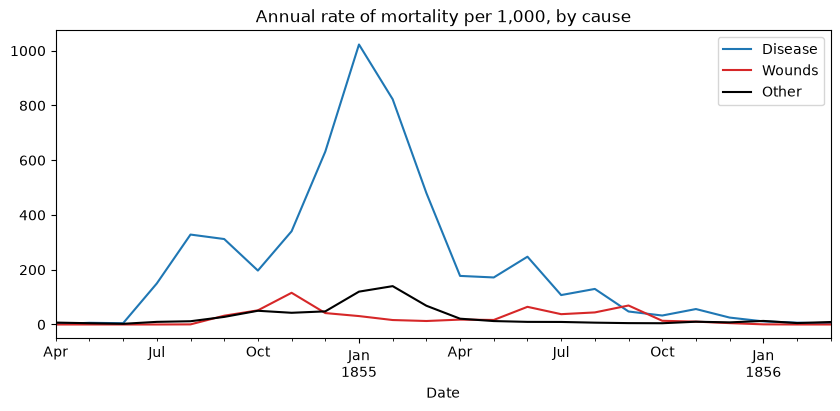

In [5]:
rates.plot.line(figsize=(10, 4), color=['tab:blue', 'tab:red', 'black'],
                title='Annual rate of mortality per 1,000, by cause')
plt.show()

The story is already here.

Deaths from disease rose to a terrible peak in January 1855, then fell to almost nothing.

Deaths from wounds were small by comparison.

So why did Nightingale draw a rose?

Keep that question in mind.

We will come back to it.

## Creating a Rose from Scratch

Pandas has no polar area plot.

So in this notebook we draw with Matplotlib directly, on **polar axes**.

On polar axes, a bar is a wedge.

Its position along the circle is an angle, `theta`, and its length is a radius, `r`.

### Angles for the months

There are 12 months in a year, so each slice takes up $2\pi / 12$ radians, or 30°.

Nightingale started each year at 9 o'clock and went clockwise.

Matplotlib can do the same with `set_theta_zero_location('W')` and `set_theta_direction(-1)`.

In [6]:
year1 = rates.loc['1854-04':'1855-03'].copy()
year2 = rates.loc['1855-04':'1856-03'].copy()

width = 2 * np.pi / 12
theta = np.arange(12) * width
labels = year1.index.strftime('%b')

theta.round(2), list(labels)

(array([0.  , 0.52, 1.05, 1.57, 2.09, 2.62, 3.14, 3.67, 4.19, 4.71, 5.24,
        5.76]),
 ['Apr',
  'May',
  'Jun',
  'Jul',
  'Aug',
  'Sep',
  'Oct',
  'Nov',
  'Dec',
  'Jan',
  'Feb',
  'Mar'])

### A simple example

Let's draw just the disease deaths in the first year, with the radius equal to the rate.

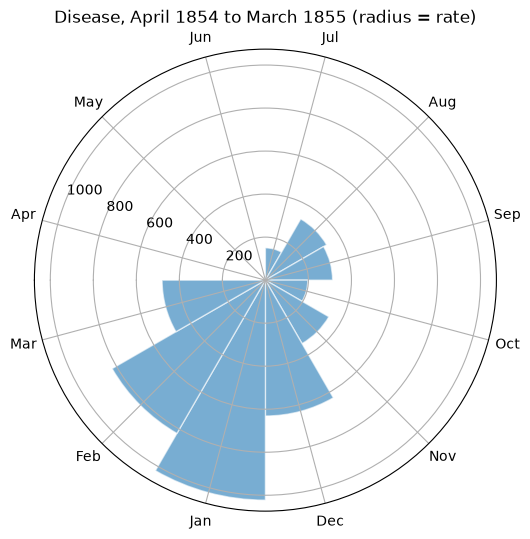

In [7]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(6, 6))
ax.set_theta_zero_location('W')
ax.set_theta_direction(-1)

ax.bar(theta, year1.Disease, width=width, align='edge', color='tab:blue', alpha=.6, edgecolor='white')

ax.set_xticks(theta + width / 2, labels)
ax.set_title('Disease, April 1854 to March 1855 (radius = rate)')
plt.show()

This is a bar chart wrapped around a circle.

But something is wrong with it.

January looks enormous compared with October.

The rate in January (1,023) is about 5 times the rate in October (197).

But the January wedge looks far more than 5 times bigger.

### Radius or area?

The eye judges a wedge by its **area**, not its radius.

And the area of a wedge grows with the *square* of its radius.

$$
\text{area} = \frac{1}{2} \, r^2 \, \Delta\theta
$$

When we double the radius, we quadruple the area.

So if the radius encodes the rate, the picture exaggerates large values.

The fix is to make the **area** proportional to the rate, which means the radius must be proportional to its **square root**.

Nightingale says so in her legend: the wedges "represent area for area" the deaths.

Let's compare the two encodings side by side.

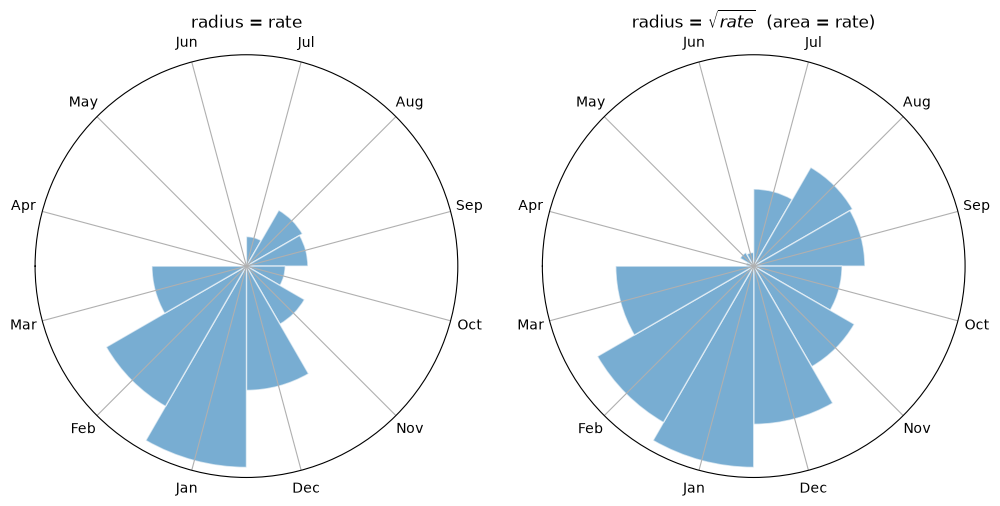

In [8]:
fig, ax = plt.subplots(1, 2, subplot_kw={'projection': 'polar'}, figsize=(12, 6))

encodings = ['radius = rate', 'radius = $\\sqrt{rate}$  (area = rate)']
for i, title in enumerate(encodings):
    r = year1.Disease if i == 0 else np.sqrt(year1.Disease)
    ax[i].set_theta_zero_location('W')
    ax[i].set_theta_direction(-1)
    ax[i].bar(theta, r, width=width, align='edge', color='tab:blue', alpha=.6, edgecolor='white')
    ax[i].set_xticks(theta + width / 2, labels)
    ax[i].set_yticks([])
    ax[i].set_title(title)

plt.show()

On the right, January is still the worst month, but October no longer looks like nothing.

The ratio of the two *areas* is now the ratio of the two rates, about 5 to 1.

```{important}
In a polar area diagram, the area of each wedge must be proportional to the value.
That means the radius must be proportional to the square root of the value.
A rose drawn with radius = value exaggerates every difference.
```

### A better example: three causes

Now let's add the other two causes.

Nightingale drew all three wedges from the center, overlapping, not stacked end to end.

So a small wedge drawn *behind* a big one would be hidden.

For now, let's put the largest wedge at the back in every month, so that nothing is hidden.

We will need a function, since we will draw several roses.

In [9]:
colors = {'Disease': '#9ecae1', 'Wounds': '#f4b6b0', 'Other': '#555555'}


def setup_rose(ax, title):
    ax.set_theta_zero_location('W')
    ax.set_theta_direction(-1)
    ax.set_xticks(theta + width / 2, labels)
    ax.set_yticks([])
    ax.spines['polar'].set_visible(False)
    ax.grid(False)
    ax.set_title(title)


def draw_rose_largest_back(ax, year):
    r = np.sqrt(year)
    order = year.rank(axis=1, ascending=False, method='first')   # 1 = largest
    for i, cause in enumerate(causes):
        for k in range(len(year)):
            ax.bar(theta[k], r[cause].iloc[k], width=width, align='edge',
                   color=colors[cause], edgecolor='white', linewidth=.5,
                   zorder=order[cause].iloc[k])

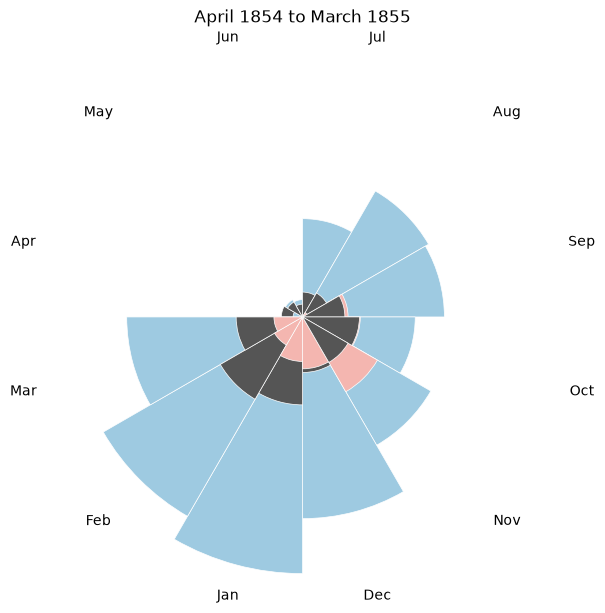

In [10]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(7, 7))
setup_rose(ax, 'April 1854 to March 1855')
draw_rose_largest_back(ax, year1)
plt.show()

The `zorder` of each wedge is its rank in its month, so the largest has `zorder=1` and is drawn first.

Notice the red wedges in September, October, and November 1854.

These are the battles of the Alma, Balaclava, and Inkerman.

Even at their worst, the wounds were a fraction of the disease.

### A more complex example: two years on one scale

Nightingale drew the second year as a separate, smaller rose.

It is smaller because fewer men died, not because it was drawn at a smaller scale.

To keep the two roses comparable, both must use the **same** radial scale.

With polar axes, we do that by giving both the same `set_rmax()`.

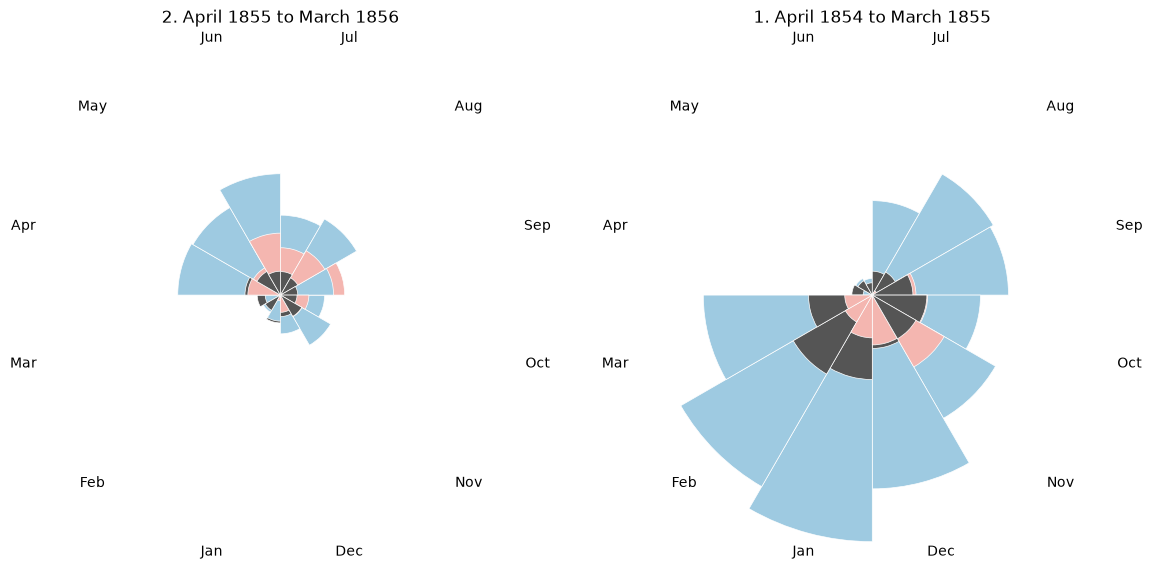

In [11]:
rmax = np.sqrt(rates.max().max())

fig, ax = plt.subplots(1, 2, subplot_kw={'projection': 'polar'}, figsize=(14, 7))
years = [year2, year1]
titles = ['2. April 1855 to March 1856', '1. April 1854 to March 1855']

for i, year in enumerate(years):
    setup_rose(ax[i], titles[i])
    draw_rose_largest_back(ax[i], year)
    ax[i].set_rmax(rmax)

plt.show()

Like Nightingale, we put the second year on the left, so the eye travels from right to left through time.

The left rose is smaller because the death rate fell.

In March 1855 a Sanitary Commission arrived from London and began cleaning the hospitals and camps, improving drains, water, and ventilation.

The blue wedges shrink month after month.

What else can you see?

## Stacking Order

Our roses put the largest wedge at the back in every month.

That is a sensible rule, and it is a **rule**.

Nightingale's engraving does not follow it.

Look closely at the original plate, and you will find that each rose has its own order.

- In the **first year**, blue is at the back, then black, then **red in front**. Red covers black even when red is bigger.
- In the **second year**, blue is at the back, then red, then **black in front**, as a dark disc.
- And a few months in the second year break even that rule.

We can record the order as data.

Let's add three columns, one per cause, holding each wedge's place in the stack: 0 at the back, 1 in the middle, 2 in front.

In [12]:
z_cols = [c + '_z' for c in causes]
stack = rates.copy()

stack.loc['1854-04':'1855-03', z_cols] = [0, 2, 1]   # year 1: red in front of black
stack.loc['1855-04':'1856-03', z_cols] = [0, 1, 2]   # year 2: black in front of red

# months that break the rule
stack.loc['1855-09', z_cols] = [1, 0, 2]   # blue over red
stack.loc['1855-11', z_cols] = [0, 2, 1]   # red over black
stack.loc['1855-12', z_cols] = [0, 2, 1]   # red over black
stack.loc['1856-03', z_cols] = [2, 0, 1]   # blue over black

stack[z_cols] = stack[z_cols].astype(int)
stack.round(1)

,Disease,Wounds,Other,Disease_z,Wounds_z,Other_z
Date,,,,,,
1854-04-01,1.4,0.0,7.0,0,2,1
1854-05-01,6.2,0.0,4.6,0,2,1
1854-06-01,4.7,0.0,2.5,0,2,1
1854-07-01,150.0,0.0,9.6,0,2,1
1854-08-01,328.5,0.4,11.9,0,2,1
1854-09-01,312.2,32.1,27.7,0,2,1
1854-10-01,197.0,51.7,50.1,0,2,1
1854-11-01,340.6,115.8,42.8,0,2,1
1854-12-01,631.5,41.7,48.0,0,2,1


These values were read off a high-resolution scan of the plate, petal by petal.

September 1855 and March 1856 are clear in the scan.

November and December 1855 are less certain, because red and black are nearly the same size in those months.

For comparison, here is the stacking that "largest at the back" would give.

In [13]:
largest_back = rates.rank(axis=1, ascending=False, method='first').astype(int) - 1
largest_back.columns = z_cols

differs = (largest_back != stack[z_cols]).any(axis=1)
pd.concat([stack[z_cols], largest_back.add_prefix('sorted_')], axis=1)[differs]

,Disease_z,Wounds_z,Other_z,sorted_Disease_z,sorted_Wounds_z,sorted_Other_z
Date,,,,,,
1854-04-01,0,2,1,1,2,0
1854-09-01,0,2,1,0,1,2
1854-10-01,0,2,1,0,1,2
1854-11-01,0,2,1,0,1,2
1855-04-01,0,1,2,0,2,1
1855-11-01,0,2,1,0,1,2
1856-01-01,0,1,2,1,2,0
1856-02-01,0,1,2,0,2,1
1856-03-01,2,0,1,1,2,0


The two orders disagree in 9 of the 24 months.

A few of those differences are invisible, because a rate of zero draws no wedge at all.

The rest change the picture.

Now let's draw a rose from the stacking table.

In [14]:
def draw_rose_stacked(ax, year, z):
    r = np.sqrt(year)
    for i, cause in enumerate(causes):
        for k in range(len(year)):
            ax.bar(theta[k], r[cause].iloc[k], width=width, align='edge',
                   color=colors[cause], edgecolor='white', linewidth=.5,
                   zorder=1 + z[cause + '_z'].iloc[k])

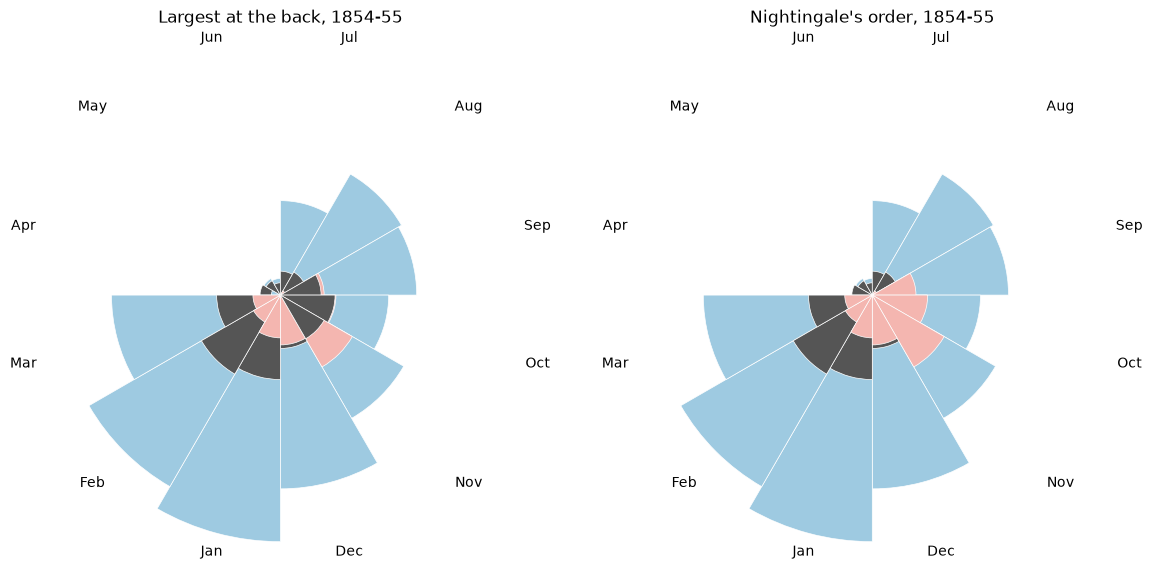

In [15]:
fig, ax = plt.subplots(1, 2, subplot_kw={'projection': 'polar'}, figsize=(14, 7))
versions = ['Largest at the back', "Nightingale's order"]

for i, title in enumerate(versions):
    setup_rose(ax[i], title + ', 1854-55')
    if i == 0:
        draw_rose_largest_back(ax[i], year1)
    else:
        draw_rose_stacked(ax[i], year1, stack.loc['1854-04':'1855-03'])
    ax[i].set_rmax(np.sqrt(year1.max().max()))

plt.show()

Look at September, October, and November 1854.

On the left, the black wedges sit in front of the red, and we can see both.

On the right, the red wedges cover the black, and the black ones disappear.

Nightingale knew this.

Her legend says: "The black line across the red triangle in Nov.r 1854 marks the boundary of the deaths from all other causes during the month."

She drew the outline of the hidden black wedge over the red one.

We can do the same, by drawing the black wedges again, unfilled, on top of everything.

The radius of each outline comes from the data, not from the picture.

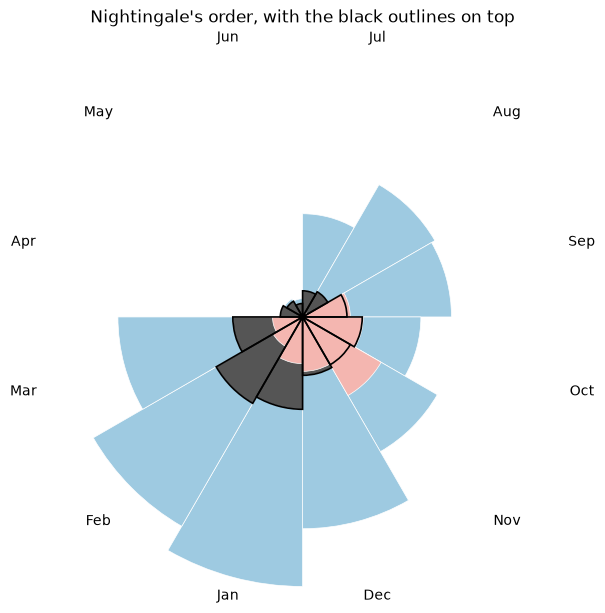

In [16]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(7, 7))
setup_rose(ax, "Nightingale's order, with the black outlines on top")
draw_rose_stacked(ax, year1, stack.loc['1854-04':'1855-03'])

ax.bar(theta, np.sqrt(year1.Other), width=width, align='edge',
       fill=False, edgecolor='black', linewidth=1.2, zorder=10)

ax.set_rmax(np.sqrt(year1.max().max()))
plt.show()

Now the November boundary shows as a black arc across the red petal.

In October 1854 the arc falls almost exactly on the red edge.

That is what Nightingale means by "the black area coincides with the red": the two rates are 50.1 and 51.7.

```{tip}
When marks overlap, their stacking order is part of the design.
It decides what the reader can see and what is hidden.
Record it as data, not as an accident of the order of your code.
```

## Reproducing the 1858 Plate

With the data, the scale, and the stacking settled, we can reproduce the plate itself.

Polar axes cannot hold two roses, the dotted line between them, and the text block.

So here we switch to ordinary axes and draw each petal as a Matplotlib `Wedge` patch.

A `Wedge` takes a center, a radius, and two angles in degrees, measured counterclockwise from 3 o'clock.

So we convert: month `i`, counted clockwise from 9 o'clock, runs from $180 - 30(i+1)$ to $180 - 30i$ degrees.

The canvas uses units of one pixel, so that positions can be measured off the scan.

In [17]:
from matplotlib.patches import Wedge
from matplotlib.textpath import text_to_path
from matplotlib import font_manager

W, H = 2576, 1409         # canvas size, in pixels at dpi=100
K = 22.5                  # radius = K * sqrt(rate), the same for both roses
PT_PER_UNIT = 72 / 100    # one canvas unit, in points

C1 = np.array([1895, 899])   # center of year 1 (right)
C2 = np.array([565, 894])    # center of year 2 (left)

PAPER, INK = '#F4EEE4', '#1E1B18'
FILL = {'Disease': '#AFCFD9', 'Wounds': '#EBD3CE', 'Other': '#7A7672'}
DOTS = {'Disease': '#86B2C2', 'Wounds': '#D8B3AC', 'Other': '#3B3936'}
EDGE = {'Disease': '#8DB6C4', 'Wounds': '#C9A39C', 'Other': '#141414'}

SANS = font_manager.FontProperties(family='DejaVu Sans', weight='bold')
SERIF = font_manager.FontProperties(family='DejaVu Serif')
SCRIPT = font_manager.FontProperties(family='DejaVu Serif', style='italic')


def month_span(i):
    return 180 - 30 * (i + 1), 180 - 30 * i


def polar_xy(center, r, deg):
    a = np.radians(deg)
    return center + r * np.array([np.cos(a), np.sin(a)])


def radius(rate):
    return K * np.sqrt(rate)

### Curved lettering

On the plate, each month's name follows the edge of its petal.

The engraver set every letter separately, turned to face away from the center.

Matplotlib has no curved text, but we can do what the engraver did.

We measure each letter's width, lay the letters along an arc, and rotate each one to the tangent.

Letters run clockwise, so the names at the bottom of each rose come out upside down, exactly as on the plate.

In [18]:
def advance(ch, size):
    prop = SANS.copy()
    prop.set_size(size)
    if ch == ' ':
        wide = text_to_path.get_text_width_height_descent('H H', prop, False)[0]
        narrow = text_to_path.get_text_width_height_descent('HH', prop, False)[0]
        return (wide - narrow) / PT_PER_UNIT
    return text_to_path.get_text_width_height_descent(ch, prop, False)[0] / PT_PER_UNIT


def curved_text(ax, center, r, mid_deg, text, size, tracking=0.2):
    lines = text.split('\n')
    for k, line in enumerate(lines):
        rk = r - k * 1.25 * size / PT_PER_UNIT      # later lines sit nearer the center
        gap = tracking * size / PT_PER_UNIT
        widths = [advance(ch, size) for ch in line]
        s = -(sum(widths) + gap * (len(line) - 1)) / 2
        for j, ch in enumerate(line):
            ang = mid_deg - np.degrees((s + widths[j] / 2) / rk)   # clockwise
            x, y = polar_xy(center, rk, ang)
            ax.text(x, y, ch, fontproperties=SANS, fontsize=size, color=INK,
                    rotation=ang - 90, rotation_mode='anchor',
                    ha='center', va='center_baseline', zorder=10)
            s += widths[j] + gap

### Drawing the petals

Each petal is drawn three times: a fill, a stipple made with a dotted `hatch`, and an edge.

The `zorder` of each petal comes straight from the stacking table.

Then the black outlines go on top of everything.

In [19]:
def draw_plate_rose(ax, year, z, center, names, label_rmin, size, pad, tracking):
    for i in range(12):
        t1, t2 = month_span(i)
        for cause in causes:
            r = radius(year[cause].iloc[i])
            zo = 2 + z[cause + '_z'].iloc[i]
            ax.add_patch(Wedge(center, r, t1, t2, facecolor=FILL[cause], edgecolor='none', zorder=zo))
            ax.add_patch(Wedge(center, r, t1, t2, facecolor='none', edgecolor=DOTS[cause],
                               hatch='....', linewidth=0, zorder=zo))
            ax.add_patch(Wedge(center, r, t1, t2, facecolor='none', edgecolor=EDGE[cause],
                               linewidth=1.6 if cause == 'Other' else 0.8, zorder=zo))
        ax.add_patch(Wedge(center, radius(year.Other.iloc[i]), t1, t2, facecolor='none',
                           edgecolor=EDGE['Other'], linewidth=1.6, zorder=8))

        r_label = max(radius(year.iloc[i].max()) + pad, label_rmin)
        curved_text(ax, center, r_label, (t1 + t2) / 2, names[i], size, tracking)

### Assembling the plate

The month names, headings, and legend are Nightingale's own words, reproduced as printed.

In [20]:
months = ['APRIL', 'MAY', 'JUNE', 'JULY', 'AUGUST', 'SEPTEMBER', 'OCTOBER',
          'NOVEMBER', 'DECEMBER', 'JANUARY', 'FEBRUARY', 'MARCH']
names1 = list(months)
names1[0], names1[9], names1[11] = 'APRIL\n1854', 'JANUARY 1855', 'MARCH 1855.'
names2 = list(months)
names2[0], names2[9] = 'APRIL 1855', 'JANUARY\n1856'

legend = [
    (0, 'The Areas of the blue, red, & black wedges are each measured from'),
    (1, 'the centre as the common vertex.'),
    (0, 'The blue wedges measured from the centre of the circle represent area'),
    (1, 'for area the deaths from Preventible or Mitigable Zymotic diseases; the'),
    (1, 'red wedges measured from the centre the deaths from wounds; & the'),
    (1, 'black wedges measured from the centre the deaths from all other causes.'),
    (0, 'The black line across the red triangle in Nov.r 1854 marks the boundary'),
    (1, 'of the deaths from all other causes during the month.'),
    (0, 'In October 1854, & April 1855, the black area coincides with the red;'),
    (1, 'in January & February 1855, the blue coincides with the black.'),
    (0, 'The entire areas may be compared by following the blue, the red & the'),
    (1, 'black lines enclosing them.'),
]

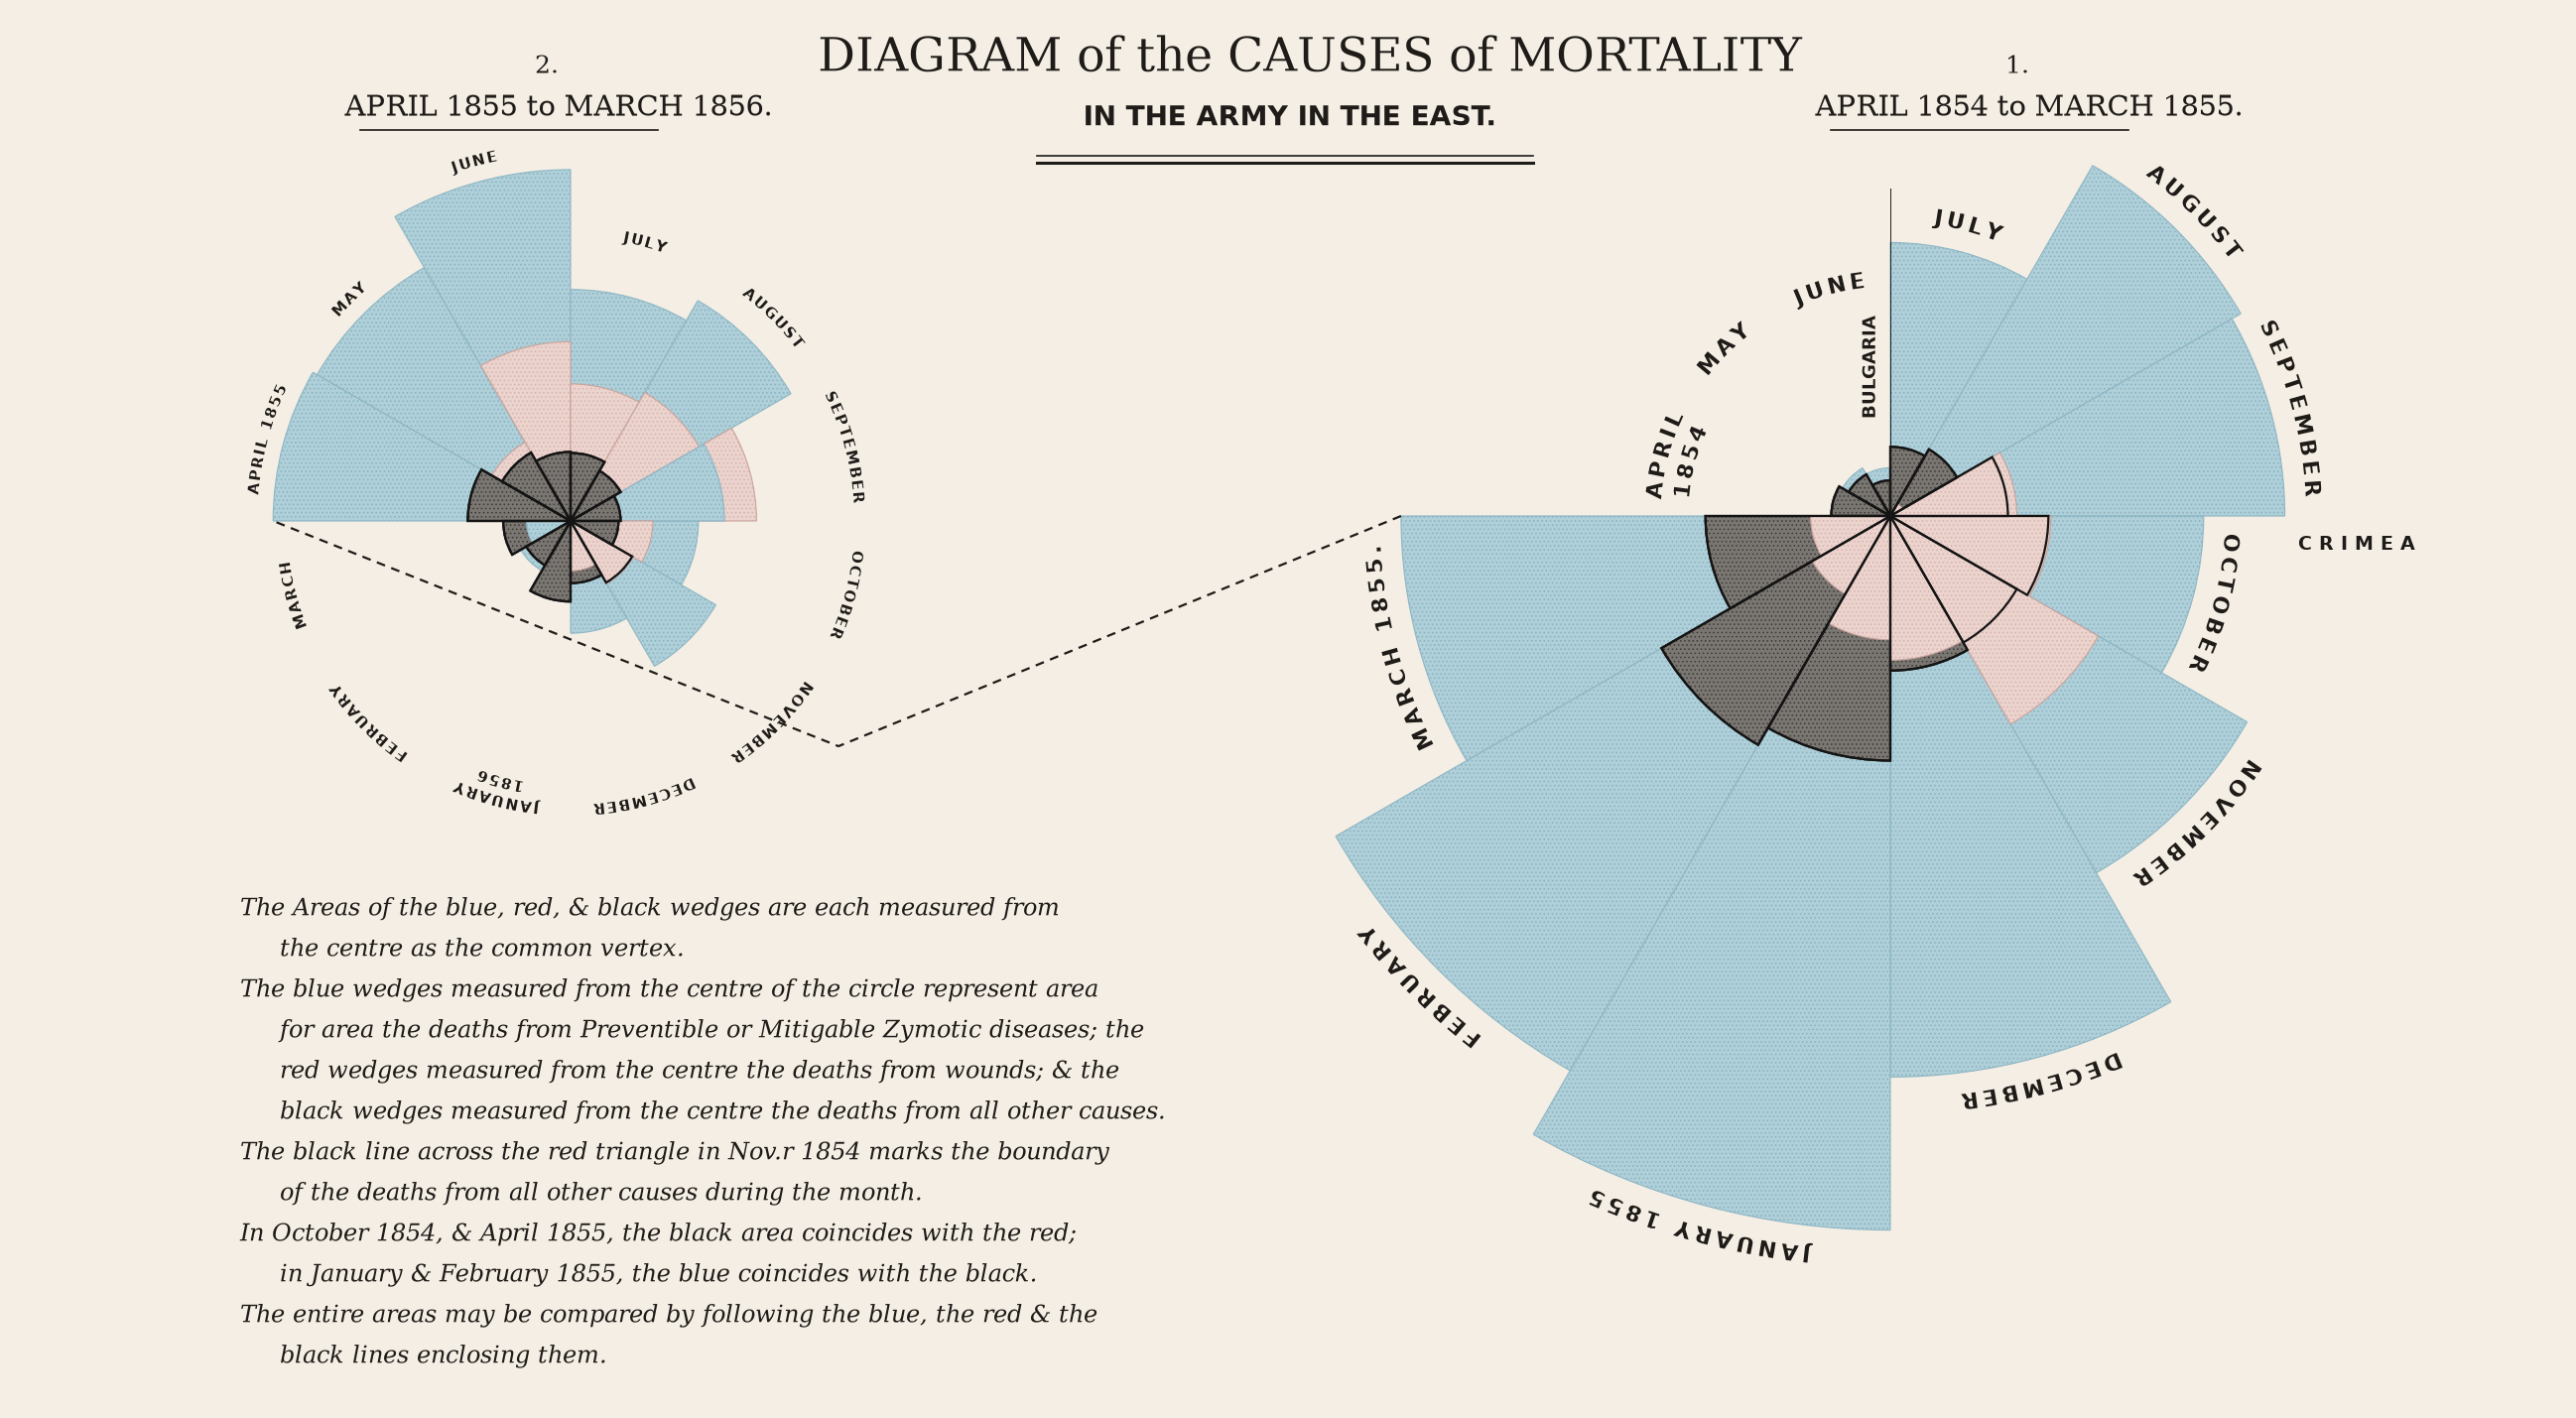

In [21]:
plt.rcParams['hatch.linewidth'] = 0.6
fig = plt.figure(figsize=(W / 100, H / 100), dpi=100, facecolor=PAPER)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect('equal')
ax.axis('off')

z1 = stack.loc['1854-04':'1855-03']
z2 = stack.loc['1855-04':'1856-03']
draw_plate_rose(ax, year1, z1, C1, names1, label_rmin=240, size=16, pad=30, tracking=0.2)
draw_plate_rose(ax, year2, z2, C2, names2, label_rmin=292, size=11, pad=22, tracking=0.12)

# where the army was
ax.plot(*np.array([C1, polar_xy(C1, 330, 90)]).T, color=INK, lw=0.7, zorder=9)
ax.text(C1[0] - 20, C1[1] + 150, 'BULGARIA', fontproperties=SANS, fontsize=13,
        rotation=90, ha='center', va='center', color=INK, zorder=10)
ax.text(C1[0] + 470, C1[1] - 34, 'C R I M E A', fontproperties=SANS, fontsize=14,
        ha='center', va='baseline', color=INK, zorder=10)

# dotted line from the end of year 1 to the start of year 2
p_end1 = polar_xy(C1, radius(year1.Disease.iloc[11]), 180)
p_start2 = polar_xy(C2, radius(year2.Disease.iloc[0]), 180)
link = np.array([p_end1, [835, 667], p_start2])
ax.plot(link[:, 0], link[:, 1], ls=(0, (4, 3)), lw=1.6, color=INK, zorder=9)

# titles
ax.text(1310, 1360, 'DIAGRAM of the CAUSES of MORTALITY', fontproperties=SERIF,
        fontsize=34, ha='center', va='center', color=INK)
ax.text(1290, 1300, 'IN THE ARMY IN THE EAST.', fontproperties=SANS,
        fontsize=20, ha='center', va='center', color=INK)
ax.plot([1035, 1535], [1262, 1262], color=INK, lw=1.2)
ax.plot([1035, 1535], [1255, 1255], color=INK, lw=2.2)

headings = [('2.', 'APRIL 1855 to MARCH 1856.', 553), ('1.', 'APRIL 1854 to MARCH 1855.', 2035)]
for i, h in enumerate(headings):
    ax.text(h[2] - 12, 1352, h[0], fontproperties=SERIF, fontsize=18, ha='center', va='center', color=INK)
    ax.text(h[2], 1310, h[1], fontproperties=SERIF, fontsize=21, ha='center', va='center', color=INK)
    ax.plot([h[2] - 200, h[2] + 100], [1288, 1288], color=INK, lw=1.2)

# legend
for i, line in enumerate(legend):
    ax.text(232 + 40 * line[0], 503 - 41 * i, line[1], fontproperties=SCRIPT,
            fontsize=17, ha='left', va='center', color=INK)

plt.show()

```{note}
This version uses Matplotlib's built-in DejaVu fonts, so it runs anywhere.
With period typefaces, such as IM Fell English for the headings, Lato Bold for the month names, and Pinyon Script for the legend, it comes much closer to the engraving.
These are free fonts from Google Fonts, loaded with `font_manager.FontProperties(fname=...)`.
```

## When the Rose Misleads

- **Radius instead of area.** If the radius encodes the value, the picture squares every difference. Many modern "Nightingale charts" make this mistake. Nightingale did not.
- **Hidden wedges.** Wedges drawn from a common center overlap. The stacking order decides which ones the reader can see. Nightingale needed an extra line to show a wedge her own order had hidden.
- **Overlap is not stacking.** The three wedges are not piled end to end, so the outer edge of a month is *not* its total. To read the total, the reader must add three areas by eye, which nobody can do.
- **Area is hard to judge.** People compare lengths more accurately than areas. Look back at the line graph: it shows the same story, and exact comparisons are easier.
- **Orientation.** Where the year starts and which way it turns are choices. Nightingale's two roses both start at 9 o'clock and turn clockwise, and the reader must be told so.
- **The two scales.** The roses are comparable only because they share one scale. If each rose filled its own circle, year 2 would look as deadly as year 1.
- **The text can be wrong too.** The legend says that "in January & February 1855, the blue coincides with the black." But in those months the disease rate was 6 to 8 times the "other" rate. In January and February **1856** the two rates are nearly equal (11.4 vs 13.0, and 6.6 vs 5.2). The legend seems to have the wrong year.

In [22]:
rates.loc[['1855-01', '1855-02', '1856-01', '1856-02'], ['Disease', 'Other']].round(1)

,Disease,Other
Date,,
1855-01-01,1022.8,120.0
1855-02-01,822.8,140.1
1856-01-01,11.4,13.0
1856-02-01,6.6,5.2


So why did Nightingale choose a rose over a line?

Her audience was not statisticians.

It was the Queen, ministers, and the public.

The rose is striking, and the vast blue area makes its point before the reader has worked out how to read it.

That is a strength in persuasion, and a weakness in analysis.

Which would you use, and for whom?

## Summary

- A **polar area diagram** puts categories around a circle and draws a wedge in each slice. It suits cyclical categories like months, hours, and directions.
- Nightingale's 1858 rose shows that most soldiers in the Crimean War died of preventable disease, not wounds.
- Use **rates**, not counts, when the size of the population changes.
- The **area** of a wedge must be proportional to the value, so the radius must be proportional to its square root.
- Pandas has no polar area plot. On Matplotlib's polar axes, `ax.bar()` draws wedges.
- Roses to be compared must share one radial scale: use the same `set_rmax()`.
- Overlapping wedges need a **stacking order**. It decides what is hidden, so record it as data and draw from it.
- Nightingale's plate uses a different stacking order for each year, and her black outline shows a wedge her own order hid.

| Task | Code |
|---|---|
| Polar axes | `plt.subplots(subplot_kw={'projection': 'polar'})` |
| Start at 9 o'clock, go clockwise | `ax.set_theta_zero_location('W')`, `ax.set_theta_direction(-1)` |
| Wedges | `ax.bar(theta, np.sqrt(values), width=2*np.pi/n, align='edge')` |
| Same scale on two roses | `ax.set_rmax(np.sqrt(values.max()))` |
| Control stacking | `zorder=` on each bar or patch |
| Outline only | `ax.bar(..., fill=False, edgecolor='black')` |
| A wedge on ordinary axes | `Wedge(center, r, theta1, theta2)` |